# Data preparation

- Builds the country-year panel
- studies missing values (where does missing values happen, and why)

In [1]:
# Set up the environment
import sys; sys.path.append('../src')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from config import *
from utils import load_panel, time_split, evaluate, log_result

## Merging the 8 raw CSVs into one panel

`build_panel.py`: 
- a table with one row per country per year (150 countries x 2010-2025 = 2,400 rows). 
- Monthly files (oil production,Brent price) are averaged to annual values. 
- The target `stress_next` looks one year ahead:it is 1 if next year's inflation is above 10%. 
- Gaps are kept as `NaN` (empty) on purpose,so we can decide how to handle them ourselves.

In [2]:
!cd .. && {sys.executable} src/build_panel.py > /dev/null
panel = pd.read_csv('../data/processed/panel.csv') 
labelled = panel.dropna(subset=['stress_next'])
print(f"Panel: {panel.shape[0]} rows x {panel.shape[1]} columns")
print(f"Rows with a target: {len(labelled)}  |  stress rate: {labelled['stress_next'].mean():.1%}")
panel.info()

zsh:1: no such file or directory: /Users/mandy/Downloads/isom3360-oil-shock


Panel: 2400 rows x 30 columns
Rows with a target: 2105  |  stress rate: 12.4%
<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   iso3                       2400 non-null   str    
 1   year                       2400 non-null   int64  
 2   country_name               2400 non-null   str    
 3   region                     2400 non-null   str    
 4   income_group               2400 non-null   str    
 5   gdp_usd                    2366 non-null   float64
 6   gdp_per_capita_usd         2366 non-null   float64
 7   gdp_growth_pct             2370 non-null   float64
 8   inflation_pct              2248 non-null   float64
 9   trade_pct_gdp              2190 non-null   float64
 10  crude_oil_import_usd       1731 non-null   float64
 11  crude_oil_export_usd       1421 non-null   float64
 12  oil_consumption_twh        2294 non-n

## Finding missing values by column

We either drop the row or **impute** it (fill it with an estimate such as the median).
First we measure how big the problem is in each column.

Some gaps are **structural** (missing by construction, not a data problem):
- `brent_yoy_pct` and `fx_change_pct` are year-on-year changes, so 2010 has no prior year;
- `inflation_next`, `stress_next`, `gdp_growth_next` are always empty for 2025, because 2026 is not observed yet.

In [3]:
ID_COLS = ['iso3', 'country_name', 'region', 'income_group', 'year']
TARGET_COLS = ['inflation_next', 'gdp_growth_next', 'stress_next']

miss_col = pd.DataFrame({
    'n_missing': panel.isna().sum(),
    'pct_missing': (panel.isna().mean() * 100).round(1),
}).drop(index=ID_COLS)
miss_col['role'] = np.where(miss_col.index.isin(TARGET_COLS), 'target', 'feature')
miss_col = miss_col.sort_values('pct_missing', ascending=False)
miss_col.to_csv(TABLES / 'missing_by_column.csv')
miss_col

,n_missing,pct_missing,role
net_crude_trade_usd,1118,46.6,feature
export_dependence_pct_gdp,982,40.9,feature
crude_oil_export_usd,979,40.8,feature
shock_x_import_burden,786,32.8,feature
import_burden_pct_gdp,673,28.0,feature
crude_oil_import_usd,669,27.9,feature
inflation_next,295,12.3,target
stress_next,295,12.3,target
fx_change_pct,262,10.9,feature
trade_pct_gdp,210,8.8,feature


**Takeaway:** the oil-trade columns are the problem. Crude exports are 41% missing and
crude imports 28%; every feature built from them (`net_crude_trade_usd`,
`export_dependence_pct_gdp`, `import_burden_pct_gdp`, `shock_x_import_burden`) inherits the
gaps. Macro columns (GDP, inflation, growth) are 1-9% missing. Brent prices are complete.

## Sorting missing values by income group

If gaps are spread evenly, dropping rows is harmless. If they cluster in certain kinds of
countries, dropping rows would **bias** the sample (e.g. leave mostly rich countries,
which rarely have inflation above 10%). We compare the missing share across World Bank
income groups.

In [4]:
FEATURE_COLS = [c for c in miss_col.index if c not in TARGET_COLS and miss_col.loc[c, 'n_missing'] > 0]
INCOME_ORDER = ['High income', 'Upper middle income', 'Lower middle income', 'Low income']

miss_income = (panel[FEATURE_COLS + TARGET_COLS].isna()
               .groupby(panel['income_group']).mean().mul(100).round(1)
               .T[INCOME_ORDER])
miss_income['all'] = miss_col['pct_missing']
miss_income.to_csv(TABLES / 'missing_by_income_group.csv')
print(panel.groupby('income_group')['iso3'].nunique()[INCOME_ORDER].rename('countries').to_string())
miss_income

income_group
High income            52
Upper middle income    46
Lower middle income    38
Low income             14


income_group,High income,Upper middle income,Lower middle income,Low income,all
net_crude_trade_usd,29.9,46.2,56.2,83.5,46.6
export_dependence_pct_gdp,24.6,38.2,52.1,79.9,40.9
crude_oil_export_usd,24.6,38.0,52.1,79.0,40.8
shock_x_import_burden,18.4,37.8,34.2,65.6,32.8
import_burden_pct_gdp,13.1,33.3,29.3,62.9,28.0
crude_oil_import_usd,13.1,33.2,29.3,61.6,27.9
fx_change_pct,6.4,11.3,13.2,20.5,10.9
trade_pct_gdp,5.4,8.4,10.7,17.0,8.8
inflation_pct,1.9,8.7,4.3,20.5,6.3
brent_yoy_pct,6.2,6.2,6.2,6.2,6.2


**Takeaway:** missingness rises steadily as income falls. Crude imports are 13% missing
for high-income countries but 62% for low-income ones; crude exports go from 25% to 79%.
Low-income countries also have the most missing labels (26%) and macro gaps (12% for GDP).
These poorer countries are exactly where inflation stress is most common, so **dropping
incomplete rows would remove many of the cases we most want to predict**. Dropping is
therefore a weak strategy for this project (we will still test it in Phase 2 as a benchmark).

## Observing missing values by year

Do gaps grow or shrink over time? This matters for our time-based split: if the test years
(2022-2024) and the 2025 rows we use for the 2026 forecast are thinner than the training
years, the model sees less information exactly when it matters.

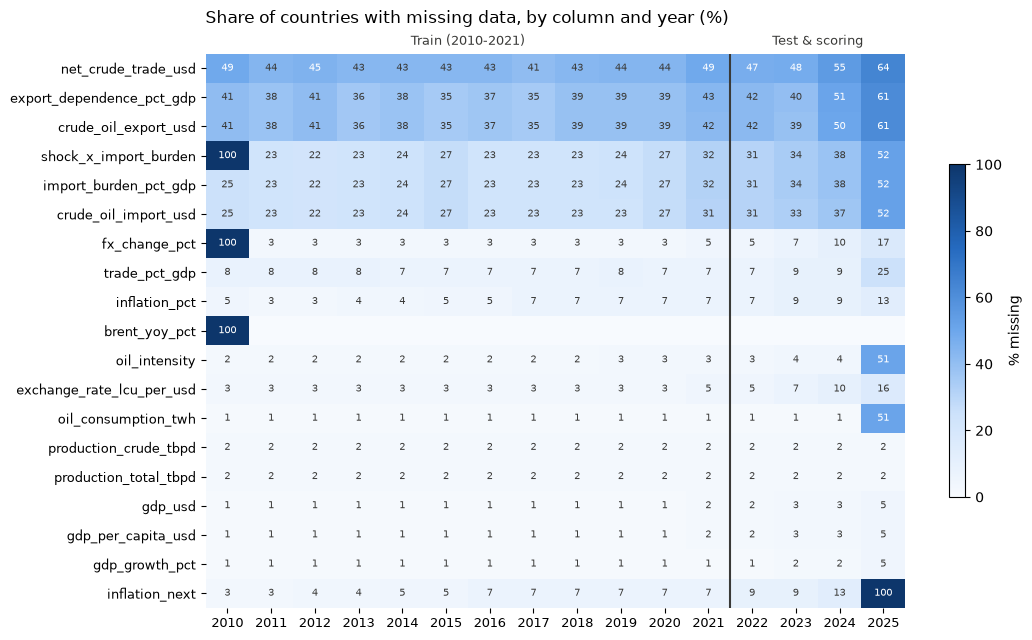

In [5]:
miss_year = panel[FEATURE_COLS + ['inflation_next']].isna().groupby(panel['year']).mean().mul(100).round(0).T
miss_year.to_csv(TABLES / 'missing_by_year.csv')

# One-hue blue scale: light = little missing, dark = mostly missing
blues = LinearSegmentedColormap.from_list('blues', ['#f7fafe', '#cde2fb', '#6da7ec', '#256abf', '#0d366b'])
fig, ax = plt.subplots(figsize=(11, 6.5))
im = ax.imshow(miss_year.values, cmap=blues, vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(len(miss_year.columns)), miss_year.columns, fontsize=9)
ax.set_yticks(range(len(miss_year.index)), miss_year.index, fontsize=9)
for i in range(miss_year.shape[0]):
    for j in range(miss_year.shape[1]):
        v = miss_year.iat[i, j]
        if v > 0:
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7,
                    color='white' if v >= 45 else '#3a3a38')
ax.axvline(11.5, color='#3a3a38', lw=1.5)  # train | test boundary
ax.text(5.5, -0.8, 'Train (2010-2021)', ha='center', fontsize=9, color='#3a3a38')
ax.text(13.5, -0.8, 'Test & scoring', ha='center', fontsize=9, color='#3a3a38')
ax.set_title('Share of countries with missing data, by column and year (%)', loc='left', pad=22)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.6, label='% missing')
fig.tight_layout()
fig.savefig(FIGURES / 'missing_values_by_year_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

**Takeaway:** missingness rises in recent years. Crude imports go from about 23% missing
in 2016-2019 to 37% in 2024 and 52% in 2025; oil consumption jumps to 51% missing in 2025
(the latest year is not fully published yet). Two consequences:
1. the test set is harder than the training set (more gaps), which we should mention when
   comparing train and test scores;
2. our 2026 risk ranking will rely more on imputed values than any earlier year. This is a
   limitation for the conclusion.

## Testing the efficiency of filling missing value as 0

A tempting shortcut is to treat a missing export value as "this country exports no crude"
(`fillna(0)`). We test this. If missing meant zero, (a) the data would contain no real
zeros and (b) countries with missing exports would not be major oil producers.

In [6]:
trade_cols = ['crude_oil_import_usd', 'crude_oil_export_usd']
print('Exact zeros in trade columns:', (panel[trade_cols] == 0).sum().to_dict())

# Large producers (>500 thousand barrels/day) with no export record
big_gap = panel[panel['crude_oil_export_usd'].isna() & (panel['production_crude_tbpd'] > 500)]
print('\nLarge crude producers with missing export value:')
display(big_gap.groupby(['iso3', 'country_name'])
        .agg(first_year=('year', 'min'), last_year=('year', 'max'), n_years=('year', 'count'),
             avg_production_tbpd=('production_crude_tbpd', 'mean'))
        .round(0).sort_values('avg_production_tbpd', ascending=False))

# Large oil consumers with no import record
big_imp_gap = panel[panel['crude_oil_import_usd'].isna()]
print('Largest oil consumers with missing import value (avg TWh in missing years):')
big_imp_gap.groupby('country_name')['oil_consumption_twh'].mean().sort_values(ascending=False).head(6).round(0)

Exact zeros in trade columns: {'crude_oil_import_usd': 0, 'crude_oil_export_usd': 0}

Large crude producers with missing export value:


,,first_year,last_year,n_years,avg_production_tbpd
iso3,country_name,,,,
SAU,Saudi Arabia,2017,2017,1,10305.0
RUS,Russian Federation,2022,2025,4,10094.0
IRQ,Iraq,2017,2025,5,4462.0
CHN,China,2025,2025,1,4325.0
IRN,"Iran, Islamic Rep.",2012,2025,4,3727.0
ARE,United Arab Emirates,2024,2025,2,3722.0
KWT,Kuwait,2012,2012,1,2635.0
VEN,"Venezuela, RB",2014,2025,12,1338.0
QAT,Qatar,2025,2025,1,1297.0


Largest oil consumers with missing import value (avg TWh in missing years):


country_name
China                   9401.0
Russian Federation      1916.0
Saudi Arabia            1904.0
Iran, Islamic Rep.       989.0
Mexico                   934.0
United Arab Emirates     585.0
Name: oil_consumption_twh, dtype: float64

**Takeaway: missing does not mean zero.** There are no zeros at all in the trade columns,
and several large producers have missing exports: Venezuela (2014-2025), Iran, Libya,
Iraq, Algeria and Russia from 2022. These gaps line up with **sanctions, conflict and
political crises**, not with "no exports". Likewise China, Saudi Arabia and Turkey have
import gaps despite heavy oil use. Filling these with 0 would tell the model that Venezuela
has no oil exposure, which is wrong. This confirms the project rule: never `fillna(0)` on
trade columns.

## Testing if the missingness means anything

If countries in trouble report less data, then "this value is missing" carries
information. We compare the stress rate (share of rows where next-year inflation > 10%) for
rows where a value is reported vs missing. If the rates differ a lot, a
**missing-indicator flag** (a 0/1 column saying "this value was missing") could help the model.

In [7]:
rows = []
for col in ['crude_oil_import_usd', 'crude_oil_export_usd', 'oil_consumption_twh', 'fx_change_pct', 'trade_pct_gdp']:
    is_miss = labelled[col].isna()
    rows.append({'column': col,
                 'n_missing_rows': int(is_miss.sum()),
                 'stress_rate_if_reported': labelled.loc[~is_miss, 'stress_next'].mean(),
                 'stress_rate_if_missing': labelled.loc[is_miss, 'stress_next'].mean()})
miss_signal = pd.DataFrame(rows).set_index('column').round(3)
miss_signal.to_csv(TABLES / 'stress_rate_by_missingness.csv')
miss_signal

,n_missing_rows,stress_rate_if_reported,stress_rate_if_missing
column,,,
crude_oil_import_usd,484,0.099,0.211
crude_oil_export_usd,772,0.115,0.141
oil_consumption_twh,15,0.124,0.133
fx_change_pct,172,0.120,0.180
trade_pct_gdp,141,0.120,0.191


**Takeaway:** rows with a missing crude-import value are about twice as likely to be stress
years (21% vs 10%). The gap is "informative": data goes missing in countries under
pressure. This supports testing **median impute + missing-indicator flags** in Phase 2,
because plain median imputation would erase this signal.

## Summary and next steps

| Finding | Implication for modelling |
|---|---|
| Trade columns 28-41% missing; macro columns under 10% | Main data-cleaning effort is on the oil-trade features |
| Gaps concentrated in middle- and low-income countries | Dropping rows biases the sample against stress cases |
| Gaps grow after 2020 and peak in 2025 | Test set and 2026 scoring are thinner than training; note as a limitation |
| Missing exports coincide with sanctions/conflict (VEN, IRN, RUS, LBY) | Missing does not mean zero; never `fillna(0)` |
| Missing imports double the stress rate | Add missing-indicator flags as features |

**What to do in future:** compare strategies (drop rows / median impute / impute + missing-indicator
flags) inside a `Pipeline` and log each with `log_result`; log-transform skewed USD columns;
check outliers in ratio features.